# Interpretability 10: Hessian

To understand the loss lanscape, we compute the hessian (loss wrt model parameters) and get its eigenvalues

Try both KAN and MLP, you will usually see that KANs have more non-zero eigenvalues than MLPs, meaning that KANs have more effective number of parameters than MLP. 

In [1]:
from xkan.utils import get_derivative
import torch
from xkan.contrib.mlp import MLP
from xkan import KANNetwork, fit
from xkan.utils import create_dataset, model2param
from xkan.viz import plot
import copy

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

f = lambda x: x[:,[0]]**2
train, test = create_dataset(f, n_var=1, train_num=1000, device=device)

inputs = train['x']
labels = train['y']

#model = MLP(width = [1,30,1])
model = KANNetwork([1,5,1], device=device)
history = fit(model, train, test, opt='adam', lr=1e-2, lamb=0.000, steps=1000)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)

cuda


train RMSE 0.0007020569766793235 test RMSE 0.0006990958834129126


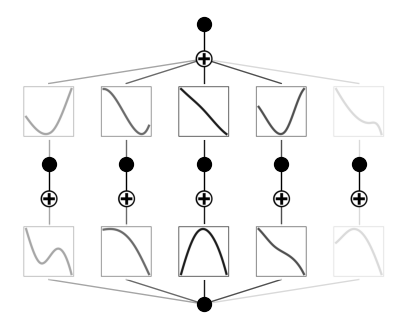

In [2]:
plot(model, train['x']);

In [3]:
hess = get_derivative(model, inputs, labels, derivative='hessian')
values, vectors = torch.linalg.eigh(hess)

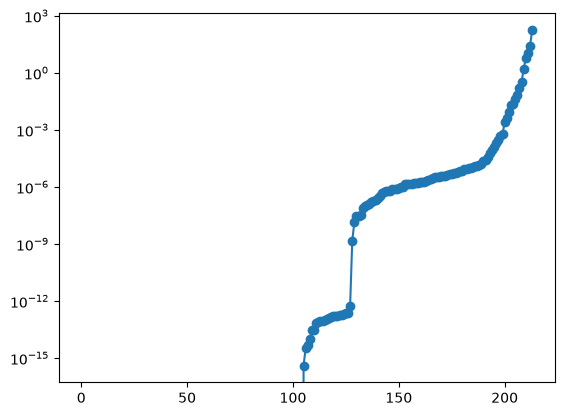

In [4]:
import matplotlib.pyplot as plt
plt.plot(values.cpu().numpy()[0], marker='o');
plt.yscale('log')